found prediction files: ['crosslingual_pred_mid.parquet', 'crosslingual_pred_strong.parquet', 'crosslingual_pred_weak.parquet']
[save] table table10_selective (6, 8)
[mid] gap=-0.0285 CI95[-0.060,+0.002] -> NOT equivalent (gap is real)
[strong] gap=+0.0034 CI95[-0.022,+0.028] -> EQUIVALENT (gap negligible)
[weak] gap=-0.0168 CI95[-0.042,+0.010] -> EQUIVALENT (gap negligible)
[save] table table10_equivalence (3, 6)
[save] table table10_selective_gap (12, 7)
[save] figure fig10_risk_coverage


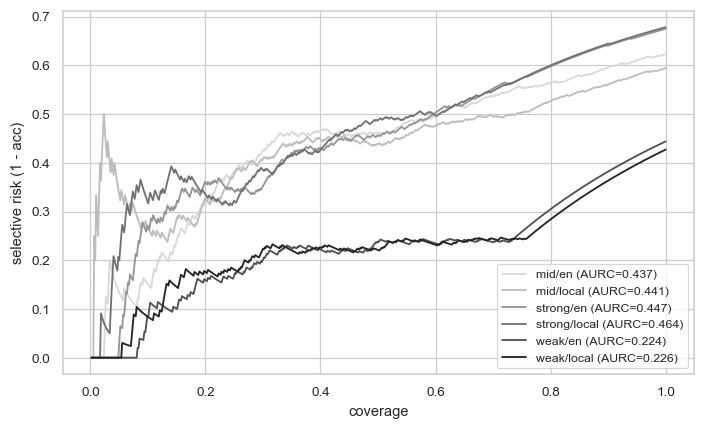

In [1]:
# ==========================================================================
# SELF-CONTAINED NOTEBOOK (single cell). The project's tested src/ modules
# are embedded (base64) and loaded in-memory, so this notebook runs on its
# own. Put the AI Hub zips in data/raw/ and your key in .env as usual.
# ==========================================================================
import sys, types, base64
from pathlib import Path
_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
_SRC = {
    'config': 'IiIiCmNvbmZpZy5weSDigJQg7ZSE66Gc7KCd7Yq4IOyghOyXrSDshKTsoJUgKOqyveuhnCDCtyDsi5zrk5wgwrcg7IOB7IiYKQoK7J6s7ZiE7ISxIOybkOy5mToKICAtIOuqqOuToCDqsr3roZzripQg7J20IO2MjOydvOydmCDsnITsuZjrpbwg6riw7KSA7Jy866GcIOqzhOyCsO2VnOuLpCjtlZjrk5zsvZTrlKkg7KCI64yA6rK966GcIOq4iOyngCkuCiAgLSDrqqjrk6Ag66y07J6R7JyEIOyLnOuTnOuKlCBTRUVEIO2VmOuCmOuhnCDthrXsnbztlZzri6QuCiAgLSDsubTthYzqs6Drpqwv652867KoIOyDgeyImOuKlCDsl6zquLDshJzrp4wg7KCV7J2Y7ZWY6rOgIOuFuO2KuOu2geydgCBpbXBvcnQg7ZW07IScIOyTtOuLpC4KIiIiCmZyb20gX19mdXR1cmVfXyBpbXBvcnQgYW5ub3RhdGlvbnMKaW1wb3J0IG9zCmltcG9ydCByYW5kb20KZnJvbSBwYXRobGliIGltcG9ydCBQYXRoCgojIC0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tCiMg6rK966GcICjsnbQg7YyM7J28OiA8UFJPSkVDVF9ST09UPi9zcmMvY29uZmlnLnB5IOq4sOykgCkKIyAtLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLQpQUk9KRUNUX1JPT1QgPSBQYXRoKF9fZmlsZV9fKS5yZXNvbHZlKCkucGFyZW50c1sxXQoKREFUQV9ESVIgICAgICA9IFBST0pFQ1RfUk9PVCAvICJkYXRhIgpSQVdfRElSICAgICAgID0gREFUQV9ESVIgLyAicmF3IiAgICAgICAgICAjIEFJIEh1YiDsm5Drs7ggemlwICjsnb3quLAg7KCE7JqpLCDsiJjsoJUg6riI7KeAKQpJTlRFUklNX0RJUiAgID0gREFUQV9ESVIgLyAiaW50ZXJpbSIgICAgICAjIO2MjOyLscK37KCV7KCcIOykkeqwhCDsgrDstpzrrLwKUFJPQ0VTU0VEX0RJUiA9IERBVEFfRElSIC8gInByb2Nlc3NlZCIgICAgIyDsmKjthqjroZzsp4Ag64W465OcL+yXo+yngCwg7KSA7IiY7YyQ7KCVIOqzqOuTnAoKUkVTVUxUU19ESVIgICA9IFBST0pFQ1RfUk9PVCAvICJyZXN1bHRzIgpGSUdVUkVTX0RJUiAgID0gUkVTVUxUU19ESVIgLyAiZmlndXJlcyIKVEFCTEVTX0RJUiAgICA9IFJFU1VMVFNfRElSIC8gInRhYmxlcyIKCmZvciBfZCBpbiAoSU5URVJJTV9ESVIsIFBST0NFU1NFRF9ESVIsIEZJR1VSRVNfRElSLCBUQUJMRVNfRElSKToKICAgIF9kLm1rZGlyKHBhcmVudHM9VHJ1ZSwgZXhpc3Rfb2s9VHJ1ZSkKCiMgLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0KIyDsnqztmITshLE6IOyLnOuTnAojIC0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tClNFRUQgPSA0MgoKZGVmIHNldF9zZWVkKHNlZWQ6IGludCA9IFNFRUQpIC0+IE5vbmU6CiAgICAiIiLrqqjrk6Ag65287J2067iM65+s66asIOyLnOuTnOulvCDtlZwg67KI7JeQIOqzoOyglS4g64W47Yq467aBIOyyqyDshYDsl5DshJwg7Zi47LacLiIiIgogICAgcmFuZG9tLnNlZWQoc2VlZCkKICAgIG9zLmVudmlyb25bIlBZVEhPTkhBU0hTRUVEIl0gPSBzdHIoc2VlZCkKICAgIHRyeToKICAgICAgICBpbXBvcnQgbnVtcHkgYXMgbnAKICAgICAgICBucC5yYW5kb20uc2VlZChzZWVkKQogICAgZXhjZXB0IEltcG9ydEVycm9yOgogICAgICAgIHBhc3MKCiMgLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0KIyDsm5Dsspwg642w7J207YSwIOyDgeyImAojIC0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tCiMgQUkgSHViIOybkOyynCB6aXAg7YyM7J2866qFIChkYXRhL3Jhdy8g7JWE656Y7JeQIOq3uOuMgOuhnCDsnITsuZgpClNPVVJDRV9aSVBTID0gWwogICAgIlRTXzFfX+uyoO2KuOuCqF8wMV9f6rec7KCcLnppcCIsCiAgICAiVFNfMV9f67Kg7Yq464KoXzAyX1/snoXrspVf64+Z7ZalLnppcCIsCiAgICAiVFNfMV9f67Kg7Yq464KoXzAzX1/tjJDroYAuemlwIiwKICAgICJUU18xX1/rsqDtirjrgqhfMDRfX+q4sOyCrC56aXAiLAogICAgIlRTXzFfX+uyoO2KuOuCqF8wNV9f7KCV67aAX+uwj1/quLDsl4VfRVNHX+yekOujjC56aXAiLAogICAgIlRTXzFfX+uyoO2KuOuCqF8wNl9f6rWt7KCcX0VTR1/snpDro4wuemlwIiwKICAgICJUU18yX1/rp5DroIjsnbTsi5zslYRfMDFfX+q3nOygnC56aXAiLAogICAgIlRTXzJfX+unkOugiOydtOyLnOyVhF8wMl9f7J6F67KVX+uPme2WpS56aXAiLAogICAgIlRTXzJfX+unkOugiOydtOyLnOyVhF8wM19f7YyQ66GALnppcCIsCiAgICAiVFNfMl9f66eQ66CI7J207Iuc7JWEXzA0X1/quLDsgqwuemlwIiwKICAgICJUU18yX1/rp5DroIjsnbTsi5zslYRfMDVfX+ygleu2gF/rsI9f6riw7JeFX0VTR1/snpDro4wuemlwIiwKICAgICJUU18yX1/rp5DroIjsnbTsi5zslYRfMDZfX+q1reygnF9FU0df7J6Q66OMLnppcCIsCl0KTEFCRUxfWklQID0gIjAyX+udvOuyqOungeuNsOydtO2EsC56aXAiCgpDQVRFR09SSUVTID0gWyLqt5zsoJwiLCAi7J6F67KVIOuPme2WpSIsICLtjJDroYAiLCAi6riw7IKsIiwgIuygleu2gCDrsI8g6riw7JeFIEVTRyDsnpDro4wiLCAi6rWt7KCcIEVTRyDsnpDro4wiXQpDT1VOVFJJRVMgID0gWyLrsqDtirjrgqgiLCAi66eQ66CI7J207Iuc7JWEIl0KRVNHX1RZUEVTICA9IFsiRSIsICJTIiwgIkciXQoKIyDsi6TsuKEg6riw7KSA6rCSIChwYXJzaW5nIOqygOymneyaqSDigJQg66Gc7Lus7JeQ7IScIOydtCDqsJLqs7wg64us65287KeA66m0IOuNsOydtO2EsCDriITrnb0g6rK96rOgKQpFWFBFQ1RFRF9TT1VSQ0VfVE9UQUwgPSA0MDA3OCAgICAgICAgICAjIOyXheuhnOuTnCDsoJzqs7XrtoQgKOqzteyLnSDsoITssrQgNTAsMDk4KQpFWFBFQ1RFRF9DQVRFR09SWV9DT1VOVFMgPSB7CiAgICAi6rec7KCcIjogOTYxNCwgIuq1reygnCBFU0cg7J6Q66OMIjogNzk4NiwgIuygleu2gCDrsI8g6riw7JeFIEVTRyDsnpDro4wiOiA3OTUxLAogICAgIuyeheuylSDrj5ntlqUiOiA3MjM0LCAi6riw7IKsIjogNDc2NCwgIu2MkOuhgCI6IDI1MjksCn0KRVhQRUNURURfQ09VTlRSWV9DT1VOVFMgPSB7IuuyoO2KuOuCqCI6IDIwMDc5LCAi66eQ66CI7J207Iuc7JWEIjogMTk5OTl9CkVYUEVDVEVEX0VTR19DT1VOVFMgPSB7IkUiOiAyNjM0MiwgIlMiOiA5MTA0LCAiRyI6IDQ2MzJ9CgojIC0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tCiMg7KSA7IiY7YyQ7KCVIOudvOuyqCDsg4HsiJggKGNvbXBsaWFuY2UgbGFiZWxpbmcpCiMgLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0KTEFCRUxfTk9OX0NPTVBMSUFOVCA9ICJOT05fQ09NUExJQU5UIgpMQUJFTF9DT01QTElBTlQgICAgID0gIkNPTVBMSUFOVCIKTEFCRUxfT1RIRVIgICAgICAgICA9ICJPVEhFUiIgICAgICAjIFBBUlRJQUwvTUlYRUQv67aI66qFIOKGkiDsnbjsoIEg6rKA7IiYCkxBQkVMX1VOTEFCRUxFRCAgICAgPSAiVU5MQUJFTEVEIiAgIyByZXN1bHQg6rO1656ACgojIOygnOyerCDsi6DtmLg6IOuqhe2Zle2VnCDsspjrsowg6rKw6rO8IOyWtO2cmC4KIyDso7zsnZgpIO2ZlO2PkCDri6jsnIQgIuuPmSIoVk5EKeydgCAn7YyQ6rKw67mE7JqpIOu2gOuLtCcg65OxIOykkeumvSDrrLjqtazsl5Drj4Qg65Ox7J6l7ZWY7JesCiMgICAgICAg6rO864ukIO2PrO2ajeydhCDsnKDrsJztlZjrr4DroZwgU0FOQ1RJT04g7Yag7YGw7JeQ7IScIOygnOyZuO2VnOuLpCjCp2xhYmVsaW5nIOyjvOyEnSDssLjsobApLgpTQU5DVElPTl9UT0tFTlMgPSBbCiAgICAi7KeV7JetIiwgIuuyjOq4iCIsICLtg5ztmJUiLCAi7IaQ7ZW067Cw7IOBIiwgIuuwsOyDgeyxheyehCIsICLtlbTqs6AiLAogICAgIuqzvO2DnOujjCIsICLrqrDsiJgiLCAi7JiB7JeF7KCV7KeAIiwgIuuTseuhney3qOyGjCIsICLst6jshowiLCAi7ZmY7IiYIiwKXQpBQ1FVSVRfVE9LRU5TID0gWwogICAgIuustOyjhCIsICLquLDqsIEiLCAi6rCB7ZWYIiwgIuuptOygnCIsICLssYXsnoQg7JeG7J2MIiwgIu2VtOuLuSDsl4bsnYwiLCAi7JeG7J2MIiwKXQoKCiMgPT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT0KIyBSRVZJU0lPTiBBREQtT05TIChSMSByZXZpc2lvbiwgMjAyNi0xMCkg4oCUIG5ldyBleHBlcmltZW50IGNvbnN0YW50cwojIC0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tCiMgS2VwdCBhcHBlbmQtb25seSBzbyBub3RlYm9va3MgMDEtMDUgYmVoYXZlIGlkZW50aWNhbGx5IHRvIHRoZSBzdWJtaXR0ZWQgcnVuLgojID09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09CgojIC0tLS0gZGV0ZXJtaW5pc3RpYyB0cmFpbi92YWwvdGVzdCBzcGxpdCBmb3IgaGVsZC1vdXQgaHlwZXItcGFyYW1ldGVyIHR1bmluZwpTUExJVF9GUkFDUyA9IHsidHJhaW4iOiAwLjUsICJ2YWwiOiAwLjI1LCAidGVzdCI6IDAuMjV9ICAjIGJ5IHF1ZXJ5CgojIC0tLS0gcmV0cmlldmFsIGNvcnB1cyAvIGV2YWwKRE9DX0NIQVJfTElNSVQgPSAzMDAwICAgICAgICAgICMgc2FtZSBoZWFkIHdpbmRvdyBhcyBuYjA0IChrZWVwIGNvbXBhcmFibGUpClJFVFJJRVZBTF9LX0xJU1QgPSAoMSwgNSwgMTApCkJPT1RTVFJBUF9OID0gMTAwMCAgICAgICAgICAgICAjIHJlc2FtcGxlcyBmb3IgQ0lzCkJPT1RTVFJBUF9DSSA9IDAuOTUKCiMgLS0tLSBkZW5zZSBtdWx0aWxpbmd1YWwgYmFzZWxpbmVzIChkb3dubG9hZGVkIG9uIHRoZSB1c2VyJ3MgbWFjaGluZSkKREVOU0VfTU9ERUxTID0gewogICAgIm1FNSI6ICAgICJpbnRmbG9hdC9tdWx0aWxpbmd1YWwtZTUtYmFzZSIsCiAgICAiQkdFLU0zIjogIkJBQUkvYmdlLW0zIiwKfQoKIyAtLS0tIFF1YWxpZmllZCBPbnRvbG9neSBBbmNob3JpbmcgKFFPQSk6IHRoZSBuLWFyeSBleHRlbnNpb24KIyBUcmlwbGUgICA6IChzdWJqZWN0LCBwcmVkaWNhdGUsIG9iamVjdCkgICAgICAgICAgICAgICAgICAgICAgLT4gQjMgbWV0YWRhdGEgYm9vc3QgKGp1cmlzZGljdGlvbiwgdG9waWMpCiMgUXVhZCAgICAgOiB0cmlwbGUgKyB0ZW1wb3JhbCB2YWxpZGl0eSBxdWFsaWZpZXIgICAgICAgICAgICAgIC0+ICsgZWZmZWN0aXZlL3Zpb2xhdGlvbi1kYXRlIGNvbnNpc3RlbmN5CiMgUGVudHVwbGUgOiBxdWFkICAgKyBzZXZlcml0eS9zdWJ0b3BpYyBxdWFsaWZpZXIgICAgICAgICAgICAgIC0+ICsgc2FuY3Rpb24tc2V2ZXJpdHkgLyBFU0ctc3VidG9waWMKUU9BX0RJTUVOU0lPTlMgPSBbImp1cmlzZGljdGlvbiIsICJ0b3BpYyIsICJ0ZW1wb3JhbCIsICJzZXZlcml0eSIsICJkb2N0eXBlIl0KUU9BX0xFVkVMUyA9IHsKICAgICJ0cmlwbGUiOiAgIFsianVyaXNkaWN0aW9uIiwgInRvcGljIl0sCiAgICAicXVhZCI6ICAgICBbImp1cmlzZGljdGlvbiIsICJ0b3BpYyIsICJ0ZW1wb3JhbCJdLAogICAgInBlbnR1cGxlIjogWyJqdXJpc2RpY3Rpb24iLCAidG9waWMiLCAidGVtcG9yYWwiLCAic2V2ZXJpdHkiLCAiZG9jdHlwZSJdLAp9CiMgdGVtcG9yYWwgZGVjYXkgY29uc3RhbnQgKHllYXJzKSBmb3IgZXhwKC18ZHR8L3RhdSkgcHJveGltaXR5ClFPQV9URU1QT1JBTF9UQVUgPSAzLjAKIyBjb29yZGluYXRlLWFzY2VudCBncmlkIGZvciBwZXItZGltZW5zaW9uIHdlaWdodHMgYWxwaGFfayAodHVuZWQgb24gdmFsIHNwbGl0KQpRT0FfQUxQSEFfR1JJRCA9IFswLjAsIDAuMSwgMC4yNSwgMC41LCAxLjAsIDIuMF0KCiMgLS0tLSBzYW5jdGlvbiBzZXZlcml0eSBidWNrZXRzIChvcmRpbmFsKSBmb3IgdGhlIHBlbnR1cGxlIHF1YWxpZmllcgpTRVZFUklUWV9PUkRFUiA9IFsiTk9ORSIsICJNSU5PUiIsICJNQUpPUiIsICJDUklNSU5BTCJdClNFVkVSSVRZX01BUCA9IHsKICAgICMgY3JpbWluYWwgLyBjdXN0b2RpYWwKICAgICLsp5Xsl60iOiAiQ1JJTUlOQUwiLCAi7YOc7ZiVIjogIkNSSU1JTkFMIiwKICAgICMgbWFqb3IgYWRtaW5pc3RyYXRpdmUgLyBmaW5hbmNpYWwKICAgICLrsozquIgiOiAiTUFKT1IiLCAi6rO87YOc66OMIjogIk1BSk9SIiwgIuyGkO2VtOuwsOyDgSI6ICJNQUpPUiIsICLrsLDsg4HssYXsnoQiOiAiTUFKT1IiLAogICAgIuyYgeyXheygleyngCI6ICJNQUpPUiIsICLrk7HroZ3st6jshowiOiAiTUFKT1IiLCAi66qw7IiYIjogIk1BSk9SIiwgIu2ZmOyImCI6ICJNQUpPUiIsICLtlbTqs6AiOiAiTUFKT1IiLAogICAgIyBtaW5vciAvIGNvcnJlY3RpdmUKICAgICLst6jshowiOiAiTUlOT1IiLCAi7Iuc7KCVIjogIk1JTk9SIiwgIuqyveqzoCI6ICJNSU5PUiIsCn0KCiMgLS0tLSBzZWxlY3RpdmUgcHJlZGljdGlvbgpTRUxFQ1RJVkVfUklTS19MRVZFTFMgPSBbMC4wNSwgMC4xMCwgMC4yMF0gICAjIHRhcmdldCByaXNrIHBvaW50cyBmb3IgY292ZXJhZ2VAcmlzawpUT1NUX01BUkdJTiA9IDAuMDUgICAgICAgICAgICAgICAgICAgICAgICAgICAgIyBlcXVpdmFsZW5jZSBtYXJnaW4gZm9yICJuZWdsaWdpYmxlIGdhcCIKCgojID09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09CiMgUkVWSVNJT04gQURELU9OUyAoUjEpOiBjYW5vbmljYWwgRW5nbGlzaCBjYXRlZ29yeS9jb3VudHJ5IG5hbWVzICsgS08tPkVOIG1hcHMKIyBOb3RlYm9vayAwMSBub3JtYWxpc2VzIHRoZSBwYXJzZWQgZGF0YSB0byB0aGVzZSBFbmdsaXNoIG5hbWVzIGJlZm9yZSBzYXZpbmcsCiMgc28gZXZlcnkgZG93bnN0cmVhbSBub3RlYm9vayBmaWx0ZXJzIG9uIEVuZ2xpc2ggYW5kIGlzIGxhbmd1YWdlLXJvYnVzdC4KIyA9PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PQpDQVRfS08yRU4gPSB7CiAgICAi6rec7KCcIjogIlJlZ3VsYXRpb24iLCAi7J6F67KVIOuPme2WpSI6ICJMZWdpc2xhdGlvbiIsICLtjJDroYAiOiAiTGVnYWwgY2FzZSIsCiAgICAi6riw7IKsIjogIk5ld3MiLCAi7KCV67aAIOuwjyDquLDsl4UgRVNHIOyekOujjCI6ICJHb3YvQ29ycCBFU0ciLAogICAgIuq1reygnCBFU0cg7J6Q66OMIjogIkludGwgRVNHIiwKfQpDVFJZX0tPMkVOID0geyLrsqDtirjrgqgiOiAiVmlldG5hbSIsICLrp5DroIjsnbTsi5zslYQiOiAiTWFsYXlzaWEifQpDT1JQVVNfQ0FURUdPUklFU19FTiA9IFsiUmVndWxhdGlvbiIsICJMZWdhbCBjYXNlIl0gICAjIHJldHJpZXZhbCBjb3JwdXMgKD0gb2xkIOq3nOygnCvtjJDroYApCkNBU0VfQ0FURUdPUllfRU4gPSAiTGVnYWwgY2FzZSIKCmRlZiBub3JtYWxpemVfY2F0X2NvdW50cnkoZGYpOgogICAgIiIiTWFwIEtvcmVhbiBjYXRlZ29yeS9jb3VudHJ5IHRvIEVuZ2xpc2ggaW4tcGxhY2Utc2FmZSAobm8tb3AgaWYgYWxyZWFkeSBFTikuIiIiCiAgICBvdXQgPSBkZi5jb3B5KCkKICAgIGlmICJjYXRlZ29yeSIgaW4gb3V0LmNvbHVtbnM6CiAgICAgICAgb3V0WyJjYXRlZ29yeSJdID0gb3V0WyJjYXRlZ29yeSJdLnJlcGxhY2UoQ0FUX0tPMkVOKQogICAgaWYgImNvdW50cnkiIGluIG91dC5jb2x1bW5zOgogICAgICAgIG91dFsiY291bnRyeSJdID0gb3V0WyJjb3VudHJ5Il0ucmVwbGFjZShDVFJZX0tPMkVOKQogICAgcmV0dXJuIG91dAo=',
    'metrics': 'IiIiCm1ldHJpY3MucHkg4oCUIOq1kOywqOyWuOyWtCDsnbzqtIDshLEg67CPIOykgOyImO2MkOyglSDtj4nqsIAg7KeA7ZGcCgrquLDtmo3shJwgQy0yIOq1rO2YhC4g7Jm467aAIOydmOyhtCDstZzshowobnVtcHnrp4wpLiBMTE0g7JiI7LihIOqysOqzvOqwgCDso7zslrTsp4DrqbQK7Ja47Ja0IOqwhCDsnbzsuZjCt+ygle2ZleuPhCDqsqnssKjCt+uztOygleyYpOywqOulvCDqs4TsgrDtlZzri6QuCiIiIgpmcm9tIF9fZnV0dXJlX18gaW1wb3J0IGFubm90YXRpb25zCmltcG9ydCBudW1weSBhcyBucAoKCmRlZiBhZ3JlZW1lbnQocHJlZF9hOiBsaXN0LCBwcmVkX2I6IGxpc3QpIC0+IGZsb2F0OgogICAgIiIi65GQIOyWuOyWtCDsmIjsuKHsnZgg64uo7IicIOydvOy5mOycqC4iIiIKICAgIGEgPSBucC5hc2FycmF5KHByZWRfYSk7IGIgPSBucC5hc2FycmF5KHByZWRfYikKICAgIGFzc2VydCBsZW4oYSkgPT0gbGVuKGIpCiAgICByZXR1cm4gZmxvYXQoKGEgPT0gYikubWVhbigpKSBpZiBsZW4oYSkgZWxzZSAwLjAKCgpkZWYgY29oZW5fa2FwcGEocHJlZF9hOiBsaXN0LCBwcmVkX2I6IGxpc3QsIGxhYmVsczogbGlzdCB8IE5vbmUgPSBOb25lKSAtPiBmbG9hdDoKICAgICIiIkNvaGVuJ3MgzrogKOyasOyXsCDrs7TsoJUg7J287LmYKS4g65GQIHJhdGVyID0g65GQIOyWuOyWtCDsmIjsuKEuIiIiCiAgICBhID0gbnAuYXNhcnJheShwcmVkX2EpOyBiID0gbnAuYXNhcnJheShwcmVkX2IpCiAgICBpZiBsYWJlbHMgaXMgTm9uZToKICAgICAgICBsYWJlbHMgPSBzb3J0ZWQoc2V0KGEudG9saXN0KCkpIHwgc2V0KGIudG9saXN0KCkpKQogICAgaWR4ID0ge2w6IGkgZm9yIGksIGwgaW4gZW51bWVyYXRlKGxhYmVscyl9CiAgICBuID0gbGVuKGEpCiAgICBpZiBuID09IDA6CiAgICAgICAgcmV0dXJuIDAuMAogICAgSyA9IGxlbihsYWJlbHMpCiAgICBjb25mID0gbnAuemVyb3MoKEssIEspKQogICAgZm9yIHgsIHkgaW4gemlwKGEsIGIpOgogICAgICAgIGNvbmZbaWR4W3hdLCBpZHhbeV1dICs9IDEKICAgIHBvID0gbnAudHJhY2UoY29uZikgLyBuCiAgICByb3cgPSBjb25mLnN1bShheGlzPTEpIC8gbgogICAgY29sID0gY29uZi5zdW0oYXhpcz0wKSAvIG4KICAgIHBlID0gZmxvYXQoKHJvdyAqIGNvbCkuc3VtKCkpCiAgICByZXR1cm4gZmxvYXQoKHBvIC0gcGUpIC8gKDEgLSBwZSkpIGlmICgxIC0gcGUpID4gMWUtMTIgZWxzZSAxLjAKCgpkZWYgYWNjdXJhY3kocHJlZDogbGlzdCwgZ29sZDogbGlzdCkgLT4gZmxvYXQ6CiAgICBwID0gbnAuYXNhcnJheShwcmVkKTsgZyA9IG5wLmFzYXJyYXkoZ29sZCkKICAgIHJldHVybiBmbG9hdCgocCA9PSBnKS5tZWFuKCkpIGlmIGxlbihwKSBlbHNlIDAuMAoKCmRlZiBhY2N1cmFjeV9nYXAocHJlZF9lbjogbGlzdCwgcHJlZF9sb2NhbDogbGlzdCwgZ29sZDogbGlzdCkgLT4gZGljdDoKICAgICIiIkFjYyhlbikgLSBBY2MobG9jYWwpOiBIMiDtlbXsi6wg7KeA7ZGcLiIiIgogICAgYWNjX2VuID0gYWNjdXJhY3kocHJlZF9lbiwgZ29sZCkKICAgIGFjY19sb2NhbCA9IGFjY3VyYWN5KHByZWRfbG9jYWwsIGdvbGQpCiAgICByZXR1cm4gewogICAgICAgICJhY2NfZW4iOiByb3VuZChhY2NfZW4sIDQpLAogICAgICAgICJhY2NfbG9jYWwiOiByb3VuZChhY2NfbG9jYWwsIDQpLAogICAgICAgICJnYXAiOiByb3VuZChhY2NfZW4gLSBhY2NfbG9jYWwsIDQpLAogICAgfQoKCmRlZiBleHBlY3RlZF9jYWxpYnJhdGlvbl9lcnJvcihjb25maWRlbmNlczogbGlzdCwgY29ycmVjdDogbGlzdCwgbl9iaW5zOiBpbnQgPSAxMCkgLT4gZmxvYXQ6CiAgICAiIiJFQ0U6IO2ZleyLoOuPhOyZgCDsi6TsoJwg7KCV64u166Wg7J2YIOq0tOumrCjqs7zsi6Ag7KeE64uoKS4iIiIKICAgIGNvbmYgPSBucC5hc2FycmF5KGNvbmZpZGVuY2VzLCBkdHlwZT1mbG9hdCkKICAgIGNvcnIgPSBucC5hc2FycmF5KGNvcnJlY3QsIGR0eXBlPWZsb2F0KQogICAgaWYgbGVuKGNvbmYpID09IDA6CiAgICAgICAgcmV0dXJuIDAuMAogICAgYmlucyA9IG5wLmxpbnNwYWNlKDAsIDEsIG5fYmlucyArIDEpCiAgICBlY2UgPSAwLjAKICAgIG4gPSBsZW4oY29uZikKICAgIGZvciBpIGluIHJhbmdlKG5fYmlucyk6CiAgICAgICAgbG8sIGhpID0gYmluc1tpXSwgYmluc1tpICsgMV0KICAgICAgICBtYXNrID0gKGNvbmYgPiBsbykgJiAoY29uZiA8PSBoaSkgaWYgaSA+IDAgZWxzZSAoY29uZiA+PSBsbykgJiAoY29uZiA8PSBoaSkKICAgICAgICBpZiBtYXNrLnN1bSgpID09IDA6CiAgICAgICAgICAgIGNvbnRpbnVlCiAgICAgICAgYWNjX2JpbiA9IGNvcnJbbWFza10ubWVhbigpCiAgICAgICAgY29uZl9iaW4gPSBjb25mW21hc2tdLm1lYW4oKQogICAgICAgIGVjZSArPSAobWFzay5zdW0oKSAvIG4pICogYWJzKGFjY19iaW4gLSBjb25mX2JpbikKICAgIHJldHVybiBmbG9hdChlY2UpCgoKZGVmIHJldHJpZXZhbF9vdmVybGFwKHRvcGtfYTogbGlzdCwgdG9wa19iOiBsaXN0KSAtPiBmbG9hdDoKICAgICIiIuyWuOyWtOuzhCB0b3AtayDqsoDsg4nqsrDqs7wgSmFjY2FyZCDspJHssqko6rO87KCcIEIg7J286rSA7ISxKS4iIiIKICAgIHNhLCBzYiA9IHNldCh0b3BrX2EpLCBzZXQodG9wa19iKQogICAgaWYgbm90IHNhIGFuZCBub3Qgc2I6CiAgICAgICAgcmV0dXJuIDEuMAogICAgcmV0dXJuIGxlbihzYSAmIHNiKSAvIGxlbihzYSB8IHNiKQoKCiMgPT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT0KIyBSRVZJU0lPTiBBREQtT05TIChSMSk6IHVuY2VydGFpbnR5LCBlcXVpdmFsZW5jZSB0ZXN0aW5nLCBzZWxlY3RpdmUgcHJlZGljdGlvbgojIC0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tCiMgUmV2aWV3ZXIgMjogTTUgKHJpc2stY292ZXJhZ2UgY3VydmVzLCBFQ0UsIHVuY2VydGFpbnR5IG9uIG1haW4gY29tcGFyaXNvbnM7CiMganVzdGlmeSAibmVnbGlnaWJsZSBnYXAiIHZpYSBhbiBlcXVpdmFsZW5jZSB0ZXN0IHdpdGggYSBzdGF0ZWQgbWFyZ2luKSBhbmQKIyBSZXN1bHRzIFE0IChDSXMgbmVlZGVkOyBhbiBvYnNlcnZlZCAwLjAwOCBkb2VzIG5vdCBlc3RhYmxpc2ggbmVnbGlnaWJpbGl0eSkuCiMgPT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT09PT0KCgpkZWYgYm9vdHN0cmFwX2NpKHZhbHVlcywgc3RhdF9mbj1ucC5tZWFuLCBuX2Jvb3Q6IGludCA9IDEwMDAsCiAgICAgICAgICAgICAgICAgY2k6IGZsb2F0ID0gMC45NSwgc2VlZDogaW50ID0gNDIpIC0+IGRpY3Q6CiAgICAiIiJOb25wYXJhbWV0cmljIGJvb3RzdHJhcCBDSSBmb3IgYSBzdGF0aXN0aWMgb3ZlciBhIDEtRCBzYW1wbGUuIiIiCiAgICBybmcgPSBucC5yYW5kb20uZGVmYXVsdF9ybmcoc2VlZCkKICAgIHggPSBucC5hc2FycmF5KHZhbHVlcywgZHR5cGU9ZmxvYXQpCiAgICBuID0gbGVuKHgpCiAgICBpZiBuID09IDA6CiAgICAgICAgcmV0dXJuIHsicG9pbnQiOiAwLjAsICJsbyI6IDAuMCwgImhpIjogMC4wLCAibiI6IDB9CiAgICBib290cyA9IG5wLmVtcHR5KG5fYm9vdCkKICAgIGZvciBiIGluIHJhbmdlKG5fYm9vdCk6CiAgICAgICAgaWR4ID0gcm5nLmludGVnZXJzKDAsIG4sIG4pCiAgICAgICAgYm9vdHNbYl0gPSBzdGF0X2ZuKHhbaWR4XSkKICAgIGxvID0gZmxvYXQobnAucXVhbnRpbGUoYm9vdHMsICgxIC0gY2kpIC8gMikpCiAgICBoaSA9IGZsb2F0KG5wLnF1YW50aWxlKGJvb3RzLCAxIC0gKDEgLSBjaSkgLyAyKSkKICAgIHJldHVybiB7InBvaW50IjogZmxvYXQoc3RhdF9mbih4KSksICJsbyI6IGxvLCAiaGkiOiBoaSwgIm4iOiBufQoKCmRlZiBwYWlyZWRfZGlmZl9jaShjb3JyZWN0X2EsIGNvcnJlY3RfYiwgbl9ib290OiBpbnQgPSAxMDAwLAogICAgICAgICAgICAgICAgICAgY2k6IGZsb2F0ID0gMC45NSwgc2VlZDogaW50ID0gNDIpIC0+IGRpY3Q6CiAgICAiIiJCb290c3RyYXAgQ0kgZm9yIHRoZSBQQUlSRUQgZGlmZmVyZW5jZSBpbiBhY2N1cmFjeSAoYWNjX2EgLSBhY2NfYikuCgogICAgY29ycmVjdF9hIC8gY29ycmVjdF9iIGFyZSAwLzEgY29ycmVjdG5lc3MgYXJyYXlzIG9uIHRoZSBTQU1FIGl0ZW1zCiAgICAoZS5nLiBFbmdsaXNoIHZzIGxvY2FsIG9uIHRoZSBzYW1lIGNhc2VzKS4gUGFpcmVkIHJlc2FtcGxpbmcga2VlcHMgdGhlCiAgICBkZXBlbmRlbmNlIHN0cnVjdHVyZSwgd2hpY2ggYW4gdW5wYWlyZWQgQ0kgd291bGQgaWdub3JlLgogICAgIiIiCiAgICBybmcgPSBucC5yYW5kb20uZGVmYXVsdF9ybmcoc2VlZCkKICAgIGEgPSBucC5hc2FycmF5KGNvcnJlY3RfYSwgZHR5cGU9ZmxvYXQpCiAgICBiID0gbnAuYXNhcnJheShjb3JyZWN0X2IsIGR0eXBlPWZsb2F0KQogICAgYXNzZXJ0IGxlbihhKSA9PSBsZW4oYiksICJwYWlyZWQgYXJyYXlzIG11c3QgYmUgZXF1YWwgbGVuZ3RoIgogICAgbiA9IGxlbihhKQogICAgaWYgbiA9PSAwOgogICAgICAgIHJldHVybiB7ImRpZmYiOiAwLjAsICJsbyI6IDAuMCwgImhpIjogMC4wLCAibiI6IDB9CiAgICBib290cyA9IG5wLmVtcHR5KG5fYm9vdCkKICAgIGZvciBpIGluIHJhbmdlKG5fYm9vdCk6CiAgICAgICAgaWR4ID0gcm5nLmludGVnZXJzKDAsIG4sIG4pCiAgICAgICAgYm9vdHNbaV0gPSBhW2lkeF0ubWVhbigpIC0gYltpZHhdLm1lYW4oKQogICAgbG8gPSBmbG9hdChucC5xdWFudGlsZShib290cywgKDEgLSBjaSkgLyAyKSkKICAgIGhpID0gZmxvYXQobnAucXVhbnRpbGUoYm9vdHMsIDEgLSAoMSAtIGNpKSAvIDIpKQogICAgcmV0dXJuIHsiZGlmZiI6IGZsb2F0KGEubWVhbigpIC0gYi5tZWFuKCkpLCAibG8iOiBsbywgImhpIjogaGksICJuIjogbn0KCgpkZWYgdG9zdF9lcXVpdmFsZW5jZShjb3JyZWN0X2EsIGNvcnJlY3RfYiwgbWFyZ2luOiBmbG9hdCA9IDAuMDUsCiAgICAgICAgICAgICAgICAgICAgIG5fYm9vdDogaW50ID0gMjAwMCwgc2VlZDogaW50ID0gNDIpIC0+IGRpY3Q6CiAgICAiIiJUd28gT25lLVNpZGVkIFRlc3RzIChUT1NUKSBmb3IgZXF1aXZhbGVuY2Ugb2YgcGFpcmVkIGFjY3VyYWNpZXMuCgogICAgSDAgKG5vbi1lcXVpdmFsZW5jZSk6IHxhY2NfYSAtIGFjY19ifCA+PSBtYXJnaW4uCiAgICBXZSByZWplY3QgSDAgKGkuZS4gY29uY2x1ZGUgRVFVSVZBTEVOQ0Ugd2l0aGluICsvLSBtYXJnaW4pIHdoZW4gdGhlCiAgICAoMS0yKmFscGhhKSBib290c3RyYXAgQ0kgb2YgdGhlIHBhaXJlZCBkaWZmZXJlbmNlIGxpZXMgZW50aXJlbHkgaW5zaWRlCiAgICAoLW1hcmdpbiwgK21hcmdpbikuIFJldHVybnMgdGhlIDkwJSBDSSAoYWxwaGE9MC4wNSBlYWNoIHNpZGUpIGFuZCBhIHZlcmRpY3QuCgogICAgVGhpcyBpcyB3aGF0IGxldHMgdGhlIHBhcGVyIHNheSAibmVnbGlnaWJsZSBnYXAiIGRlZmVuc2libHksIGluc3RlYWQgb2YKICAgIGluZmVycmluZyBpdCBmcm9tIGEgc2luZ2xlIHBvaW50IGVzdGltYXRlIG9mIDAuMDA4LgogICAgIiIiCiAgICByZXMgPSBwYWlyZWRfZGlmZl9jaShjb3JyZWN0X2EsIGNvcnJlY3RfYiwgbl9ib290PW5fYm9vdCwgY2k9MC45MCwgc2VlZD1zZWVkKQogICAgZXF1aXZhbGVudCA9IChyZXNbImxvIl0gPiAtbWFyZ2luKSBhbmQgKHJlc1siaGkiXSA8IG1hcmdpbikKICAgIHJldHVybiB7ImRpZmYiOiByZXNbImRpZmYiXSwgImNpOTBfbG8iOiByZXNbImxvIl0sICJjaTkwX2hpIjogcmVzWyJoaSJdLAogICAgICAgICAgICAibWFyZ2luIjogbWFyZ2luLCAiZXF1aXZhbGVudCI6IGJvb2woZXF1aXZhbGVudCksICJuIjogcmVzWyJuIl19CgoKZGVmIHJpc2tfY292ZXJhZ2VfY3VydmUoY29uZmlkZW5jZXMsIGNvcnJlY3QpOgogICAgIiIiU2VsZWN0aXZlLXByZWRpY3Rpb24gcmlzay1jb3ZlcmFnZSBjdXJ2ZS4KCiAgICBTb3J0IGl0ZW1zIGJ5IERFU0NFTkRJTkcgY29uZmlkZW5jZTsgYXQgZWFjaCBwcmVmaXggKGNvdmVyYWdlID0gZnJhY3Rpb24KICAgIGFuc3dlcmVkKSBjb21wdXRlIHJpc2sgPSAxIC0gYWNjdXJhY3kgb24gdGhlIGFuc3dlcmVkIHN1YnNldC4KICAgIFJldHVybnMgYXJyYXlzIChjb3ZlcmFnZSwgcmlzaykgcGx1cyBBVVJDIChhcmVhIHVuZGVyIHJpc2stY292ZXJhZ2UpLgogICAgIiIiCiAgICBjb25mID0gbnAuYXNhcnJheShjb25maWRlbmNlcywgZHR5cGU9ZmxvYXQpCiAgICBjb3JyID0gbnAuYXNhcnJheShjb3JyZWN0LCBkdHlwZT1mbG9hdCkKICAgIG4gPSBsZW4oY29uZikKICAgIGlmIG4gPT0gMDoKICAgICAgICByZXR1cm4geyJjb3ZlcmFnZSI6IG5wLmFycmF5KFtdKSwgInJpc2siOiBucC5hcnJheShbXSksICJhdXJjIjogMC4wfQogICAgb3JkZXIgPSBucC5hcmdzb3J0KC1jb25mKQogICAgY29ycl9zb3J0ZWQgPSBjb3JyW29yZGVyXQogICAgY3VtX2NvcnJlY3QgPSBucC5jdW1zdW0oY29ycl9zb3J0ZWQpCiAgICBrID0gbnAuYXJhbmdlKDEsIG4gKyAxKQogICAgY292ZXJhZ2UgPSBrIC8gbgogICAgcmlzayA9IDEuMCAtIGN1bV9jb3JyZWN0IC8gawogICAgX3RyYXB6ID0gZ2V0YXR0cihucCwgInRyYXBlem9pZCIsIGdldGF0dHIobnAsICJ0cmFweiIsIE5vbmUpKQogICAgYXVyYyA9IGZsb2F0KF90cmFweihyaXNrLCBjb3ZlcmFnZSkpCiAgICByZXR1cm4geyJjb3ZlcmFnZSI6IGNvdmVyYWdlLCAicmlzayI6IHJpc2ssICJhdXJjIjogYXVyY30KCgpkZWYgY292ZXJhZ2VfYXRfcmlzayhjb25maWRlbmNlcywgY29ycmVjdCwgdGFyZ2V0X3Jpc2s6IGZsb2F0KSAtPiBmbG9hdDoKICAgICIiIk1heGltdW0gY292ZXJhZ2UgYWNoaWV2YWJsZSB3aGlsZSBrZWVwaW5nIHNlbGVjdGl2ZSByaXNrIDw9IHRhcmdldC4iIiIKICAgIHJjID0gcmlza19jb3ZlcmFnZV9jdXJ2ZShjb25maWRlbmNlcywgY29ycmVjdCkKICAgIGNvdiwgcmlzayA9IHJjWyJjb3ZlcmFnZSJdLCByY1sicmlzayJdCiAgICBvayA9IGNvdltyaXNrIDw9IHRhcmdldF9yaXNrXQogICAgcmV0dXJuIGZsb2F0KG9rLm1heCgpKSBpZiBsZW4ob2spIGVsc2UgMC4wCgoKZGVmIHNlbGVjdGl2ZV9hY2N1cmFjeShwcmVkcywgZ29sZCwgY29uZmlkZW5jZXMsIHRocmVzaG9sZDogZmxvYXQpOgogICAgIiIiQWNjdXJhY3kgb24gaXRlbXMgd2hvc2UgY29uZmlkZW5jZSA+PSB0aHJlc2hvbGQsIHBsdXMgY292ZXJhZ2UuIiIiCiAgICBwID0gbnAuYXNhcnJheShwcmVkcykKICAgIGcgPSBucC5hc2FycmF5KGdvbGQpCiAgICBjID0gbnAuYXNhcnJheShjb25maWRlbmNlcywgZHR5cGU9ZmxvYXQpCiAgICBtYXNrID0gYyA+PSB0aHJlc2hvbGQKICAgIGNvdiA9IGZsb2F0KG1hc2subWVhbigpKSBpZiBsZW4oYykgZWxzZSAwLjAKICAgIGFjYyA9IGZsb2F0KChwW21hc2tdID09IGdbbWFza10pLm1lYW4oKSkgaWYgbWFzay5zdW0oKSBlbHNlIDAuMAogICAgcmV0dXJuIHsidGhyZXNob2xkIjogdGhyZXNob2xkLCAiY292ZXJhZ2UiOiBjb3YsICJzZWxlY3RpdmVfYWNjIjogYWNjLAogICAgICAgICAgICAibl9hbnN3ZXJlZCI6IGludChtYXNrLnN1bSgpKX0K',
}
_ORDER = ['config', 'metrics']
for _n in _ORDER:
    _m = types.ModuleType(_n)
    _m.__dict__["__file__"] = str(_ROOT / "src" / (_n + ".py"))
    sys.modules[_n] = _m
    exec(compile(base64.b64decode(_SRC[_n]).decode("utf-8"), _n + ".py", "exec"), _m.__dict__)
from config import *   # paths, constants, normalize_cat_country, set_seed
# --------------------------------------------------------------------------

# ---- shared setup (paths, seed, plotting) ---------------------------------
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from config import (INTERIM_DIR, PROCESSED_DIR, TABLES_DIR, FIGURES_DIR,
                    RETRIEVAL_K_LIST, QOA_LEVELS, QOA_DIMENSIONS, DENSE_MODELS,
                    BOOTSTRAP_N, TOST_MARGIN, SELECTIVE_RISK_LEVELS, set_seed)
set_seed()
matplotlib.rcParams.update({"axes.unicode_minus": False, "figure.dpi": 110})
# Figure convention: seaborn, grayscale, no titles, dpi=600, save PNG + PDF.
sns.set_theme(style="whitegrid", context="paper")
sns.set_palette("Greys_r")
GREY_DARK, GREY_MID, GREY_LIGHT = "#333333", "#777777", "#BBBBBB"
FIG_DPI = 600
def save_fig(fig, stem):
    for ext in ("png", "pdf"):
        fig.savefig(FIGURES_DIR / f"{stem}.{ext}", dpi=FIG_DPI, bbox_inches="tight")
    print("[save] figure", stem)
def save_tbl(df, stem):
    df.to_csv(TABLES_DIR / f"{stem}.csv", index=False, encoding="utf-8-sig")
    print("[save] table", stem, df.shape)


# 1. Load available per-case predictions (nb05 cross-lingual)
import glob
from metrics import (risk_coverage_curve, coverage_at_risk, selective_accuracy,
                     expected_calibration_error, tost_equivalence, paired_diff_ci)

pred_files = sorted(glob.glob(str(PROCESSED_DIR / "crosslingual_pred_*.parquet")))
print("found prediction files:", [Path(f).name for f in pred_files])
assert pred_files, "Run nb05 first (need crosslingual_pred_<tier>.parquet)."
preds = {Path(f).stem.replace("crosslingual_pred_", ""): pd.read_parquet(f) for f in pred_files}


# 2. Risk–coverage, AURC, coverage@risk, ECE per tier x language
rows = []
curves = {}
for tier, df in preds.items():
    for lang in ["en", "local"]:
        pred = df[f"pred_{lang}"].to_numpy()
        conf = df[f"conf_{lang}"].to_numpy()
        gold = df["gold"].to_numpy()
        correct = (pred == gold).astype(int)
        rc = risk_coverage_curve(conf, correct)
        curves[(tier, lang)] = rc
        row = {"tier": tier, "lang": lang,
               "accuracy": round(correct.mean(), 4),
               "AURC": round(rc["aurc"], 4),
               "ECE": round(expected_calibration_error(conf, correct), 4)}
        for r in SELECTIVE_RISK_LEVELS:
            row[f"cov@risk{r}"] = round(coverage_at_risk(conf, correct, r), 4)
        rows.append(row)
sel = pd.DataFrame(rows)
save_tbl(sel, "table10_selective")
sel


# 3. Equivalence test: is the en-vs-local accuracy gap really negligible?
rows = []
for tier, df in preds.items():
    ce = (df["pred_en"].to_numpy() == df["gold"].to_numpy()).astype(int)
    cl = (df["pred_local"].to_numpy() == df["gold"].to_numpy()).astype(int)
    diff = paired_diff_ci(ce, cl, n_boot=BOOTSTRAP_N)
    tost = tost_equivalence(ce, cl, margin=TOST_MARGIN, n_boot=2000)
    rows.append({"tier": tier, "gap(en-local)": round(diff["diff"], 4),
                 "ci95_lo": round(diff["lo"], 4), "ci95_hi": round(diff["hi"], 4),
                 "tost_margin": TOST_MARGIN, "equivalent": tost["equivalent"]})
    verdict = "EQUIVALENT (gap negligible)" if tost["equivalent"] else "NOT equivalent (gap is real)"
    print(f"[{tier}] gap={diff['diff']:+.4f} CI95[{diff['lo']:+.3f},{diff['hi']:+.3f}] -> {verdict}")
eq = pd.DataFrame(rows)
save_tbl(eq, "table10_equivalence")
eq


# 4. Selective-accuracy gap (en vs local) after abstaining below a threshold
rows = []
for tier, df in preds.items():
    for thr in [0.0, 0.5, 0.7, 0.9]:
        se = selective_accuracy(df["pred_en"], df["gold"], df["conf_en"], thr)
        sl = selective_accuracy(df["pred_local"], df["gold"], df["conf_local"], thr)
        rows.append({"tier": tier, "threshold": thr,
                     "sel_acc_en": round(se["selective_acc"], 4),
                     "sel_acc_local": round(sl["selective_acc"], 4),
                     "sel_gap": round(se["selective_acc"] - sl["selective_acc"], 4),
                     "cov_en": round(se["coverage"], 3), "cov_local": round(sl["coverage"], 3)})
sg = pd.DataFrame(rows)
save_tbl(sg, "table10_selective_gap")
sg


# 5. Figure: risk-coverage curves
rc_rows = []
for (tier, lang), rc in curves.items():
    for cov_v, risk_v in zip(rc["coverage"], rc["risk"]):
        rc_rows.append({"series": f"{tier}/{lang} (AURC={rc['aurc']:.3f})",
                        "coverage": cov_v, "risk": risk_v})
rc_df = pd.DataFrame(rc_rows)
fig, ax = plt.subplots(figsize=(6.5, 4))
if len(rc_df):
    n_series = rc_df["series"].nunique()
    sns.lineplot(data=rc_df, x="coverage", y="risk", hue="series",
                 palette=sns.color_palette("Greys", n_colors=max(n_series + 1, 3))[1:],
                 ax=ax)
ax.set_xlabel("coverage"); ax.set_ylabel("selective risk (1 - acc)")
ax.legend(fontsize=8, title="")
plt.tight_layout(); save_fig(fig, "fig10_risk_coverage"); plt.show()
